# EAD back-testing by utilisation band and the LGD and EAD validation battery

**Question:** Where do the EAD models of a revolving-line book fail when they are back-tested in currency by utilisation band, and do the engine's LGD tests of calibration and discrimination judge the small-business LGD ladder in the same way?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 03 and 05 of this topic (the LGD ladder and the CCF estimators)
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- back-test an EAD model in currency by utilisation band with `ead_backtest_by_band`, compute the band gaps by hand, and read its metric, statistic and light;
- fit the three families of EAD model on generated revolving lines, back-test them on lines they have not seen, and see which model fails in which band and how the band edges move the metric;
- run the three LGD tests of the engine, `lgd_calibration_by_segment`, `lgd_calibration_over_time` and `lgd_discrimination`, compute their statistics by hand on a small example and read their lights;
- read the committed LGD battery of C08 for the 2014-19 cohort, check its Bonferroni adjustment from the rows it stores, and say why calibration and discrimination can disagree.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Put the pipeline on the import path, import the packages and print their versions
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.validation import lgd_ead as tests

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.c09 import estimators, generator
from pipeline.cases.c09 import models as ead_models

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Three committed artifacts and one generator. `data/derived/C09/level-3.json` is the revolving-lines generator of case C09 at acceleration level 3 (a known truth: synthetic lines, not any lender's); this notebook reads from it the plan of the replications and the utilisation bands of the committed back-test, and the committed metrics to set beside its own. `data/derived/C08/dc-2014-19.json` is the C08 variant for the defaults of 2014 to 2019 (a charge-off indicator on the SBA 7(a) small-business loans, notebook 01), with the LGD tests of the six ladder rungs in `tests`. The third, `data/derived/C08/dc-2020-23.json`, is read only for its number of loans in step 6.

The EAD lines themselves are drawn in the notebook, with the case's generator and its own fitting functions (`data-pipeline/pipeline/cases/c09`), from the seeds of the committed plan: three development replications to fit the models and four test replications, of 50,000 facilities each, to back-test them. The engine's LGD and EAD tests are plain functions whose lights are **Contraste internal gates, not regulatory thresholds** (their docstrings say so): each states its rule, and the pipeline records the parameters with the result.

In [2]:
# Open the artifacts and print the versions, the committed plan, the bands and the models of the back-test
c09 = json.loads((ROOT / "data" / "derived" / "C09" / "level-3.json").read_text(encoding="utf-8"))
c08 = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2014-19.json").read_text(encoding="utf-8"))
c08_next = json.loads((ROOT / "data" / "derived" / "C08" / "dc-2020-23.json").read_text(encoding="utf-8"))
gen = json.loads((ROOT / "data" / "derived" / "C09" / "models-generator.json").read_text(encoding="utf-8"))["fit"]
plan = gen["replications_plan"]
bt = c09["outputs"]["ead_backtest"]
versions = (c09["provenance"]["riskvalidation_version"], c08["provenance"]["riskvalidation_version"])
print("C09, C08, installed:", *versions, rv.__version__)
print("bands of utilisation:", bt["bands"], "|", bt["currency"])
print("models back-tested:", sorted({r["model_id"] for r in bt["rows"]}))
light = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

C09, C08, installed: 1.0.1 1.0.1 1.0.1
bands of utilisation: [0.0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 4.0] | USD
models back-tested: ['ccf-cohort-floor-cap', 'ccf-fixed-horizon-bounded-scale', 'ccf-fixed-horizon-censor', 'ccf-fixed-horizon-floor-cap', 'ccf-fixed-horizon-none', 'ccf-variable-horizon-floor-cap', 'direct-ead', 'utilisation-change']


## Method

### Step 1: the EAD back-test by band, by hand

An EAD model is judged in currency, not only as a factor (the research follows Tong et al. 2016 and Qi 2009 in this). The engine groups the facilities by utilisation band $[u_b, u_{b+1})$ (the last band is closed) and, for each band $b$ with predicted EADs $\hat{E}_i$ and realised EADs $E_i$:

$$\text{gap}_b = \sum_{i \in b}\hat{E}_i - \sum_{i \in b}E_i, \qquad \text{relative gap}_b = \frac{\text{gap}_b}{\sum_{i \in b}E_i}, \qquad \text{metric} = \max_b |\text{relative gap}_b|$$

The statistic is the relative gap of the total. The light is a Contraste internal gate: green when the metric is at most 0.10, amber up to 0.25, red above (`gap_amber` and `gap_red`, recorded with the result; the p-value is null). A band with no facility, or with a realised EAD of zero, does not enter the metric. (All from the docstring of `ead_backtest_by_band`.)

The cell invents six facilities in three bands, computes each band by hand and runs the engine on the same arrays.

In [3]:
# Six invented facilities in three utilisation bands: the band gaps by hand and then the engine's ead_backtest_by_band
utilisation = np.array([0.10, 0.15, 0.30, 0.35, 0.60, 0.90])
predicted = np.array([1_000.0, 1_200.0, 2_000.0, 2_200.0, 4_000.0, 5_000.0])
realised = np.array([1_100.0, 1_150.0, 2_500.0, 2_400.0, 3_600.0, 4_700.0])
edges = np.array([0.0, 0.2, 0.4, 1.0])
relative = []
for k in range(3):
    inside = (utilisation >= edges[k]) & ((utilisation < edges[k + 1]) | (k == 2))
    gap = predicted[inside].sum() - realised[inside].sum()
    relative.append(gap / realised[inside].sum())
    print(f"band [{edges[k]}, {edges[k + 1]}): n={inside.sum()} predicted {predicted[inside].sum():7.1f}"
          f" realised {realised[inside].sum():7.1f} relative gap {relative[-1]:8.4f}")
total = (predicted.sum() - realised.sum()) / realised.sum()
print(f"metric by hand (max absolute relative gap): {max(abs(r) for r in relative):.4f}")
print(f"relative gap of the total: {total:.4f}")
res = tests.ead_backtest_by_band(predicted, realised, utilisation, edges, model_id="invented")
print(f"engine: metric {res.metric:.4f} | statistic {res.statistic:.4f} | {light[res.light.value]}")

band [0.0, 0.2): n=2 predicted  2200.0 realised  2250.0 relative gap  -0.0222
band [0.2, 0.4): n=2 predicted  4200.0 realised  4900.0 relative gap  -0.1429
band [0.4, 1.0): n=2 predicted  9000.0 realised  8300.0 relative gap   0.0843
metric by hand (max absolute relative gap): 0.1429
relative gap of the total: -0.0032
engine: metric 0.1429 | statistic -0.0032 | amber


### Step 2: back-test the three families on generated lines

The research for this product compares three families of EAD model: a conversion factor applied to the undrawn amount, a direct model of the EAD over the limit, and a model of the change of utilisation. The next cell draws the lines of level 3, fits the eight models of the case on the development replications (CCF constants for each design and treatment, a bounded-scale CCF model, `fit_direct_ead` and `fit_utilisation_change`) and predicts the test replications with the case's own `predict`. The next cell then asks the engine for the back-test of each model on the test lines.

In [4]:
# Draw the lines of level 3, fit the eight models on development replications and predict the test replications
designs = ("fixed-horizon", "cohort", "variable-horizon")
dev_lines = [generator.generate(seed, 3, 50_000) for seed in plan["development_seeds"][:3]]
test_lines = [generator.generate(seed, 3, 50_000) for seed in plan["test_seeds"][:4]]
dev = {d: estimators.join([estimators.observe(x, d) for x in dev_lines]) for d in designs}
test = {d: estimators.join([estimators.observe(x, d) for x in test_lines]) for d in designs}
fits = ead_models.fit_models(dev)
predictions = {}
for model_id, fit in fits.items():
    obs = test[ead_models.MODEL_DESIGN[model_id]]
    predictions[model_id] = ead_models.predict(fit, obs)
n_dev = sum(x.n_defaults for x in dev_lines)
n_test = sum(x.n_defaults for x in test_lines)
print("development defaulters:", n_dev, "|", "test:", n_test)
print("models fitted:", list(fits))

development defaulters: 5893 | test: 7665
models fitted: ['ccf-fixed-horizon-none', 'ccf-fixed-horizon-censor', 'ccf-fixed-horizon-floor-cap', 'ccf-fixed-horizon-bounded-scale', 'ccf-cohort-floor-cap', 'ccf-variable-horizon-floor-cap', 'direct-ead', 'utilisation-change']


The fits and the predictions are ready. The next cell scores each model on the test lines with `ead_backtest_by_band`, using the bands of the committed back-test, and prints the metric beside the one that the artifact committed over twenty replications.

In [5]:
# Back-test each model on the test lines with ead_backtest_by_band and set the metric beside the committed one
edges = np.array(bt["bands"])
committed = {t["model_id"]: t["metric"] for t in c09["tests"] if t["test_id"] == "lgd_ead.ead_backtest_by_band"}
results = {}
print(f"{'model':34s} {'metric':>8s} {'light':>9s} {'committed (20 replications)':>30s}")
for model_id in fits:
    obs = test[ead_models.MODEL_DESIGN[model_id]]
    util = obs.drawn_ref / obs.limit_ref
    results[model_id] = tests.ead_backtest_by_band(predictions[model_id], obs.ead, util, edges, model_id=model_id)
    r = results[model_id]
    print(f"{model_id:34s} {r.metric:8.4f} {light[r.light.value]:>9s} {committed[model_id]:30.4f}")

model                                metric     light    committed (20 replications)
ccf-fixed-horizon-none               0.0403     green                         0.0230
ccf-fixed-horizon-censor             0.0416     green                         0.0476
ccf-fixed-horizon-floor-cap          0.0221     green                         0.0190
ccf-fixed-horizon-bounded-scale      0.0231     green                         0.0156
ccf-cohort-floor-cap                 0.2462     amber                         0.2033
ccf-variable-horizon-floor-cap       0.0350     green                         0.0305
direct-ead                           0.5695       red                         0.5719
utilisation-change                   0.2270     amber                         0.2195


Before the figure, a design question the metric hides: how much does it depend on the band edges? The engine takes the edges as an argument, so the same predictions can be scored on a coarse grid of three bands and on the fine grid of seven. The cell does this for the three families that the figure will draw.

In [6]:
# Score three models on a coarse and on the fine grid of bands
coarse = np.array([0.0, 0.8, 1.0, 4.0])
three = ("ccf-fixed-horizon-floor-cap", "direct-ead", "utilisation-change")
print(f"{'model':34s} {'fine grid (7 bands)':>26s} {'coarse grid (3 bands)':>28s}")
for model_id in three:
    obs = test[ead_models.MODEL_DESIGN[model_id]]
    util = obs.drawn_ref / obs.limit_ref
    on_coarse = tests.ead_backtest_by_band(predictions[model_id], obs.ead, util, coarse, model_id=model_id)
    print(f"{model_id:34s} {results[model_id].metric:26.4f} {on_coarse.metric:28.4f}")

model                                     fine grid (7 bands)        coarse grid (3 bands)
ccf-fixed-horizon-floor-cap                            0.0221                       0.0148
direct-ead                                             0.5695                       0.4655
utilisation-change                                     0.2270                       0.2270


Coarser bands that are unions of the fine ones average the gaps of neighbouring utilisation levels and can only make the metric smaller, never larger, so a back-test that reports one number owes the reader its band edges. The figure now draws the relative gap by band on the fine grid, which is where the failure is located.

ccf-fixed-horizon-floor-cap    worst band [0.0, 0.2) relative gap +0.022
direct-ead                     worst band [1.5, 4.0) relative gap -0.570
utilisation-change             worst band [0.8, 1.0) relative gap +0.227


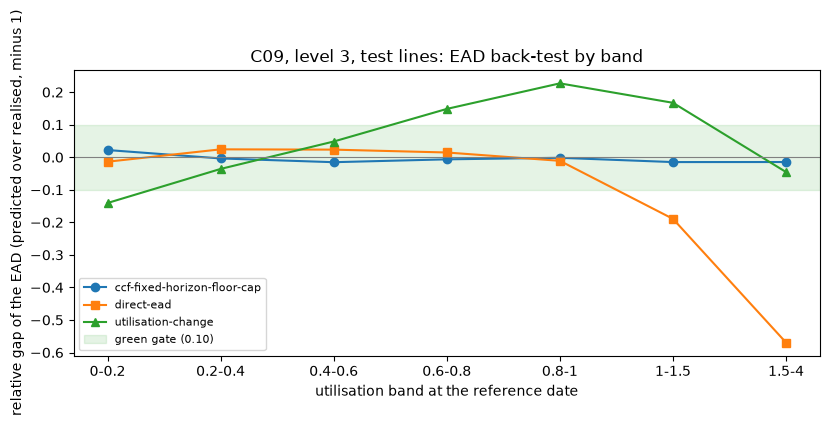

In [7]:
# Draw the relative gap by utilisation band for three of the models
fig, ax = plt.subplots(figsize=(8.4, 3.8))
labels = [f"{lo:g}-{hi:g}" for lo, hi in zip(edges[:-1], edges[1:])]
for model_id, marker in zip(three, ("o", "s", "^")):
    bands = results[model_id].extras["bands"]
    gaps = [band["relative_gap"] for band in bands]
    ax.plot(range(len(gaps)), gaps, marker=marker, label=model_id)
    worst = max(bands, key=lambda band: abs(band["relative_gap"] or 0.0))
    edge = f"[{worst['lower']}, {worst['upper']})"
    print(f"{model_id:30s} worst band {edge} relative gap {worst['relative_gap']:+.3f}")
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.axhspan(-0.10, 0.10, color="tab:green", alpha=0.12, label="green gate (0.10)")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels)
ax.set_xlabel("utilisation band at the reference date")
ax.set_ylabel("relative gap of the EAD (predicted over realised, minus 1)")
ax.set_title("C09, level 3, test lines: EAD back-test by band")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The bands are in utilisation at the reference date, so the right-hand bands hold lines that were already fully drawn or over their limit. The direct model fails there: it predicts a share of the limit and cannot exceed it, while the lines over their limit end above it, so its gap in the highest band is large and negative. The factor model stays within the green band almost everywhere, since it applies a constant share to whatever undrawn amount a line has, and the utilisation-change model leaves the band in the bands where the balance is already close to the limit. One metric per model would name the failing model; the figure says which lines it fails on.

### Step 4: the three LGD tests on a small example, by hand

The engine's LGD tests take the realised and the predicted LGD of each loan. The cell invents twelve loans (realised and predicted values written out) so that every intermediate is visible, and computes by hand what the first and third test compute:

- `lgd_calibration_by_segment`: a paired t-test of the gap $d_i = \text{realised}_i - \text{predicted}_i$, $t = \bar d / (s_d / \sqrt{N})$ with $N - 1$ degrees of freedom and a two-sided p-value; the metric is $\bar d$; the light is green when the p-value is at least 0.05, amber from 0.01 and red below.
- `lgd_discrimination`: the Spearman rank correlation $\rho$ of predicted and realised LGD, which is the Pearson correlation of the ranks (ties by average rank); the light is green when $\rho \ge 0.30$, amber from 0.10, red below, a Contraste gate, because LGD rank power is modest in the literature.

(The rules and gates are those of the docstrings of the two functions.) The p-value of the t statistic comes from the engine, which uses the t distribution; the notebook computes the statistic itself.

In [8]:
# Twelve invented loans: the paired t statistic and the Spearman correlation by hand, then the engine's two tests
real = np.array([0.55, 0.70, 0.40, 0.90, 0.62, 0.35, 0.80, 0.58, 0.66, 0.48, 0.75, 0.52])
pred = np.array([0.50, 0.60, 0.45, 0.70, 0.61, 0.40, 0.65, 0.55, 0.52, 0.51, 0.62, 0.47])
d = real - pred
n = d.size
mean_d, sd_d = d.mean(), d.std(ddof=1)
se = sd_d / np.sqrt(n)
print(f"N={n} | mean gap {mean_d:.4f} | standard deviation {sd_d:.4f}")
print(f"standard error {se:.4f} | t = {mean_d / se:.4f}")
rank = np.argsort(np.argsort(real)) + 1.0, np.argsort(np.argsort(pred)) + 1.0
rho = np.corrcoef(rank[0], rank[1])[0, 1]
print(f"ranks of the realised values: {rank[0].astype(int).tolist()}")
print(f"ranks of the predicted values: {rank[1].astype(int).tolist()} | Spearman by hand = {rho:.4f}")

by_segment = tests.lgd_calibration_by_segment(real, pred, segment="invented")
rank_test = tests.lgd_discrimination(real, pred, segment="invented")
low, high = by_segment.extras["ci_low"], by_segment.extras["ci_high"]
sig = light[by_segment.light.value]
print(f"lgd_calibration_by_segment: t={by_segment.statistic:.4f} p={by_segment.p_value:.4f} {sig}")
print(f"95% interval of the mean gap: ({low:.4f}, {high:.4f})")
print(f"lgd_discrimination: rho={rank_test.statistic:.4f} p={rank_test.p_value:.4g} {light[rank_test.light.value]}")

N=12 | mean gap 0.0608 | standard deviation 0.0834
standard error 0.0241 | t = 2.5271
ranks of the realised values: [5, 9, 2, 12, 7, 1, 11, 6, 8, 3, 10, 4]
ranks of the predicted values: [4, 8, 2, 12, 9, 1, 11, 7, 6, 5, 10, 3] | Spearman by hand = 0.9441
lgd_calibration_by_segment: t=2.5271 p=0.0281 amber
95% interval of the mean gap: (0.0079, 0.1138)
lgd_discrimination: rho=0.9441 p=3.927e-06 green


### Step 5: the same loans over time

`lgd_calibration_over_time(realised, predicted, period)` runs the paired t-test inside each period (a default year or a cohort index), keeps the periods with at least two observations and a nonzero spread, and combines them:

$$\text{statistic} = \max_k |t_k|, \qquad p = \min\big(1,\; K\,\min_k p_k\big), \qquad \text{metric} = \max_k |\bar d_k|$$

with $K$ the number of periods tested (a Bonferroni adjustment, so that looking at several periods does not inflate the chance of a false alarm). A period with zero spread and a gap other than zero makes the light red. The cell assigns the twelve loans to three years of four, runs the test and checks the adjustment from the period rows the engine returns.

In [9]:
# Run lgd_calibration_over_time on the twelve loans in three years and check the Bonferroni adjustment from its rows
period = np.repeat([2019, 2020, 2021], 4)
over_time = tests.lgd_calibration_over_time(real, pred, period, model_id="invented")
for row in over_time.extras["periods"]:
    print(f"period {row['period']}: n={row['n']} mean gap {row['mean_gap']:.4f} t={row['t']:.4f} p={row['p']:.4f}")
k = over_time.extras["n_periods_tested"]
p_min = min(r["p"] for r in over_time.extras["periods"])
print(f"K={k} | statistic (largest |t|) {over_time.statistic:.4f} | p = min(1, K * min p) = {min(1.0, k * p_min):.4f}")
print(f"engine p {over_time.p_value:.4f} | {light[over_time.light.value]}")

period 2019: n=4 mean gap 0.0750 t=1.4412 p=0.2452
period 2020: n=4 mean gap 0.0350 t=0.8347 p=0.4651
period 2021: n=4 mean gap 0.0725 t=1.8280 p=0.1650
K=3 | statistic (largest |t|) 1.8280 | p = min(1, K * min p) = 0.4950
engine p 0.4950 | green


### Step 6: the committed LGD battery of C08, 2014-19

The C08 variant keeps the engine's test rows for each ladder rung: calibration by segment (the whole cohort is the segment), discrimination, and calibration over time. The over-time test of a cutoff variant runs over every default after the training cutoff, so its periods are the default years and its number of loans is larger than the cohort's; the cell checks that figure. It then prints, for the six rungs, the mean gap with its p-value and light, the Spearman correlation with its light and the over-time statistic, and verifies the Bonferroni adjustment from the stored period rows of the fractional-logit rung.

In [10]:
# Print the committed battery of the six rungs for the 2014-19 cohort and the Bonferroni arithmetic of the stored rows
rows = {(t["model_id"], t["test_id"].split(".")[1]): t for t in c08["tests"] if t["model_id"]}
n_cohort = c08["outputs"]["lgd_distribution"]["n"]
n_next = c08_next["outputs"]["lgd_distribution"]["n"]
over = rows[("L2-fractional-logit", "lgd_calibration_over_time")]
total = n_cohort + n_next
print(f"loans in 2014-19: {n_cohort:,} | in 2020-23: {n_next:,} | sum: {total:,}")
print(f"loans in the over-time test: {over['n']:,}")
short = {"L1-ols": "OLS", "L2-fractional-logit": "fractional logit", "L3-beta": "beta", "L4-hurdle": "two-stage",
         "L5-gradient-boosted": "boosted trees", "L6-tobit": "Tobit"}
lt = "light"
print(f"{'rung':18s} {'gap':>9s} {'p':>10s} {lt:>8s} | {'Spearman':>8s} {lt:>8s} | {'max |t|':>8s} {lt:>8s}")
names = ("lgd_calibration_by_segment", "lgd_discrimination", "lgd_calibration_over_time")
for rung in short:
    a, b_, c = (rows[(rung, name)] for name in names)
    left = f"{short[rung]:18s} {a['metric']:9.4f} {a['p_value']:10.2e} {light[a['light']]:>8s}"
    middle = f"{b_['metric']:8.4f} {light[b_['light']]:>8s}"
    print(left, "|", middle, "|", f"{c['statistic']:8.3f} {light[c['light']]:>8s}")
periods = over["extras"]["periods"]
p_min = min(r["p"] for r in periods)
print(f"fractional logit: K={len(periods)} | min p = {p_min:.3e} | K * min p = {len(periods) * p_min:.3e}")
print(f"committed p = {over['p_value']:.3e}")

loans in 2014-19: 36,481 | in 2020-23: 13,930 | sum: 50,411
loans in the over-time test: 50,411
rung                     gap          p    light | Spearman    light |  max |t|    light
OLS                   0.0058   8.46e-05      red |   0.4390    green |    7.066      red
fractional logit      0.0164   4.37e-28      red |   0.4399    green |   10.799      red
beta                  0.0138   2.88e-20      red |   0.4257    green |    9.555      red
two-stage             0.0165   1.45e-28      red |   0.4405    green |   10.845      red
boosted trees         0.0300   1.85e-96      red |   0.5139    green |   17.831      red
Tobit                 0.0167   1.88e-29      red |   0.4376    green |    9.229      red
fractional logit: K=10 | min p = 4.991e-27 | K * min p = 4.991e-26
committed p = 4.991e-26


The mean gap is positive for every rung and the calibration light is red for every rung, while the Spearman correlation is above the green gate for all of them: the models order the loans acceptably and place their level too low. The light is set by the p-value, not by the size of the gap: with 36,481 loans a gap well under a percentage point is already red. The last figure shows the gap by default year for the fractional-logit rung, which is where the over-time test finds its largest t.

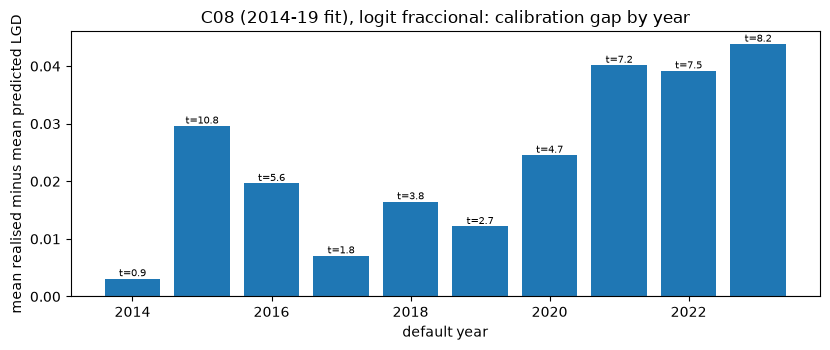

In [11]:
# Draw the mean gap by default year of the fractional-logit rung, with the t statistic of each year
fig, ax = plt.subplots(figsize=(8.4, 3.6))
years = [r["period"] for r in periods]
ax.bar(years, [r["mean_gap"] for r in periods], color="tab:blue")
for r in periods:
    ax.annotate(f"t={r['t']:.1f}", (r["period"], r["mean_gap"]), ha="center", va="bottom", fontsize=7)
ax.axhline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("default year")
ax.set_ylabel("mean realised minus mean predicted LGD")
ax.set_title("C08 (2014-19 fit), logit fraccional: calibration gap by year")
fig.tight_layout()
plt.show()

## Results

**Answer:** Back-tested on lines the models have not seen, the factor model with floor and cap stays within 0.0221 of the realised EAD in every band (green), the utilisation-change model is amber at 0.2270 and worst in the band from 0.8 to 1.0 (+0.227), and the direct model is red at 0.5695 and worst in the band from 1.5 to 4.0 (-0.570); scoring the same predictions on three coarse bands lowers the direct model's metric to 0.4655 and the factor model's to 0.0148. On the C08 cohort 2014-19 the engine's tests give a red calibration light to all six rungs (mean gaps from 0.0058 to 0.0300) and a green discrimination light to all of them (Spearman from 0.4257 to 0.5139): the models order the loans and place the level too low.

- **The back-test is a worked formula.** On the six invented facilities the band gaps are -0.0222, -0.1429 and 0.0843, so the metric is 0.1429 (amber) and the relative gap of the total is only -0.0032: a total can look right while a band is wrong. The engine returns the same numbers.
- **The models fail in different places.** On the generated test lines the fixed-horizon factor models are green (0.0221 to 0.0416), the variable-horizon one too (0.0350), the cohort design is amber at 0.2462, the utilisation-change model amber at 0.2270 and the direct EAD model red at 0.5695, the lines over their limit that it cannot predict. The committed metrics over twenty replications are of the same order, for example 0.2033 for the cohort design and 0.5719 for the direct model.
- **The band edges are part of the result.** On the coarse grid the factor model scores 0.0148 against 0.0221 on the fine one and the direct model 0.4655 against 0.5695, while the utilisation-change model keeps 0.2270 because its worst band is a band of both grids.
- **Every LGD test can be computed by hand.** On the twelve invented loans the mean gap is 0.0608 with a standard deviation of 0.0834 and a standard error of 0.0241, so t = 2.5271 and the engine's p-value is 0.0281 (amber); the Spearman correlation is 0.9441 by hand and by the engine (green).
- **The over-time test is a Bonferroni-adjusted maximum.** With three periods the largest |t| is 1.8280 and the adjusted p-value 0.4950, which is three times the smallest period p-value.
- **C08, 2014-19: calibration is red for every rung and discrimination is green for every rung.** The mean gaps run from 0.0058 to 0.0300 with p-values from 8.46e-05 to 1.85e-96, the Spearman correlations from 0.4257 to 0.5139, and the over-time statistics from 7.066 to 17.831. The light is set by the p-value, not by the size of the gap: with 36,481 loans a gap of 0.0058 is already red. The over-time test covers 50,411 loans, the sum of the 2014-19 and 2020-23 cohorts, and its adjustment checks out on the stored rows (K = 10, 10 times 4.991e-27 equals the committed 4.991e-26).

What the notebook does not do: it does not recompute the loan-level LGD rows of C08, which are not committed; the C08 battery is read as committed. The generated lines are synthetic and the invented loans and facilities show the arithmetic only. The next notebook sets these results beside the benchmark evidence.

## Summary

- An EAD model is back-tested in currency by utilisation band: the band gaps, their relative size, and the largest of them as the metric, with a green gate at 0.10 and a red one at 0.25 that are Contraste's own. The band edges are an argument of the test, and coarser edges can only lower the metric.
- Fitted and back-tested on generated lines, the factor model passes in every band, the utilisation-change model leaves the band where the balance is near the limit, and the direct model fails on the lines over their limit because it cannot predict above it.
- The LGD tests are a paired t on the mean gap, a Spearman correlation against fixed gates, and a Bonferroni-adjusted paired t over time; each can be computed by hand on a small example.
- In C08 the calibration light is red for every rung while discrimination is green: calibration and ranking are different questions, and the battery asks both.

**What to try next.** Change the predicted EADs of step 1 so that one band moves from green to amber and then red, and change the coarse edges of step 2 to see the metric move; then continue with notebook 07, which sets the C08 and C09 results beside the benchmark evidence in the literature.

## References

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: the document behind the PD tests of topic 01; the LGD and EAD tests of this notebook follow the engine's own docstrings and gates. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2017), Basel III: Finalising post-crisis reforms (d424). https://www.bis.org/bcbs/publ/d424.htm
- Tong, E. N. C., Mues, C., Brown, I. and Thomas, L. C. (2016), Exposure at default models with and without the credit conversion factor, European Journal of Operational Research 252(3). https://doi.org/10.1016/j.ejor.2016.01.054
- Loterman, G., Brown, I., Martens, D., Mues, C. and Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Spearman, C. (1904), The proof and measurement of association between two things, American Journal of Psychology 15(1). https://doi.org/10.2307/1412159
- The engine's own documentation of `ead_backtest_by_band`, `lgd_calibration_by_segment`, `lgd_calibration_over_time` and `lgd_discrimination` (release 0.8.1), which states every rule and gate quoted above.
- This repository: `docs/design/SDD.md` (cases C08 and C09), `data/derived/C09/level-3.json` and `data/derived/C08/dc-2014-19.json`.